    Age  StudyHours  Attendance  PreviousMarks  AssignmentScore Result
0    18         2.5        75.0            NaN               55      p
1    19         4.0        82.0            NaN               68      p
2    20         5.0        85.0           47.0               78      p
3    21         6.0        88.0           89.0               46      f
4    22         5.5        87.0           90.0               87      p
5    23         4.0        78.0           85.0               91      p
6    24         3.0        75.0           79.0               80      p
7    25         7.0        80.0           81.0               69      p
8    26         2.0        76.0           69.0               45      f
9    27         3.4        87.0           83.0               82      p
10   28         5.0         NaN           85.0               79      p
11   21         6.0        88.0           89.0               46      f
12   22         5.5        87.0           90.0               87      p
   Age

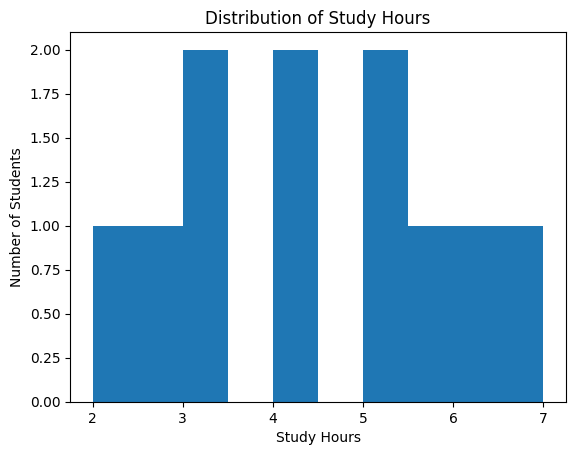

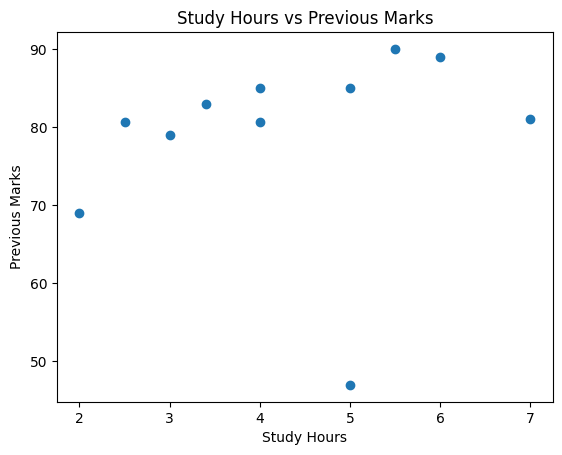

   Age  StudyHours  Attendance  ...  AssignmentScore  Result PerformanceScore
0   18         2.5        75.0  ...               55       p        71.254545
1   19         4.0        82.0  ...               68       p        77.254545
2   20         5.0        85.0  ...               78       p        67.700000
3   21         6.0        88.0  ...               46       f        75.800000
4   22         5.5        87.0  ...               87       p        88.200000

[5 rows x 7 columns]
0     p
1     p
2     p
3     f
4     p
5     p
6     p
7     p
8     f
9     p
10    p
Name: Result, dtype: object
0     1
1     1
2     1
3     0
4     1
5     1
6     1
7     1
8     0
9     1
10    1
Name: Result, dtype: int64
[0 1 1]
   Actual  Predicted
3       0          0
5       1          1
4       1          1
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00

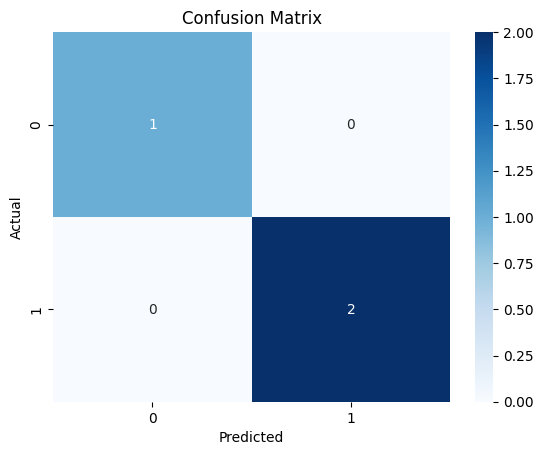

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,precision_score
from sklearn.metrics import recall_score,f1_score
from sklearn.metrics import confusion_matrix,classification_report
data=pd.read_csv("data3.csv")
print(data)
print(data.head())
print(data.shape)
print(data.columns)
print(data.dtypes)
print(data.describe())
print(data.isnull().sum())
print(data.duplicated().sum())
data["Attendance"]=data["Attendance"].fillna(data["Attendance"].mean())
data["PreviousMarks"]=data["PreviousMarks"].fillna(data["PreviousMarks"].mean())
print(data.isnull().sum())
data=data.drop_duplicates()
print(data.duplicated().sum())
#perfrom basic data visualization
plt.hist(data["StudyHours"])
plt.xlabel("Study Hours")
plt.ylabel("Number of Students")
plt.title("Distribution of Study Hours")
plt.show()
#visualization between studyhours and previous Marks
plt.scatter(data["StudyHours"],data["PreviousMarks"])
plt.xlabel("Study Hours")
plt.ylabel("Previous Marks")
plt.title("Study Hours vs Previous Marks")
plt.show()
#feature engineering
data["PerformanceScore"]=(
    0.4* data['PreviousMarks']+
    0.3*data['Attendance']+
    0.3*data['AssignmentScore']
)
print(data.head())
X=data[
    ["StudyHours","PreviousMarks","Attendance","AssignmentScore","PerformanceScore"]
]
y=data["Result"]
print(y)
y=y.map({"p":1,"f":0})
print(y)
#spilt the dataset
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)
#select ml algorithm
model=DecisionTreeClassifier(
   max_depth=3,
   random_state=42
)
#train model
model.fit(X_train,y_train)
#make predictions
y_pred=model.predict(X_test)
print(y_pred)
#compare actual and predicated values
result=pd.DataFrame({"Actual":y_test,"Predicted":y_pred})
print(result)
#evaluate the model
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)
precision=precision_score(y_test,y_pred)
print("Precision:",precision)
recall=recall_score(y_test,y_pred)
print("Recall:",recall)
f1=f1_score(y_test,y_pred)
print("F1 Score:",f1)
#dispaly classification report
print(classification_report(y_test,y_pred))
cm=confusion_matrix(y_test,y_pred)
print(cm)
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()